# 04 v2 · How NextBrain labels become Allen labels, label by label

This notebook takes [04_to_allen.ipynb](04_to_allen.ipynb) further. It uses the **real test
segmentations** in `data/basics/changed_recon_0.2mm` (5 cases, 0.2 mm, about 300 labels each)
and explains:

1. **The algorithm, step by step**: what `nextbrain_utils.to_allen.get_nextbrain2allen_map`
   and `to_allen` do with each label.
2. **The rule that converts each label** in the test data. There is one table with all
   300 labels: rule, Allen ID, Allen name and position in the Allen tree.
3. **The problematic labels**: why each one fails and how it is fixed.
4. **A fixed conversion (`to_allen_v2`)**: library map + an explicit, checked list of overrides.
   It is applied to the test cases.

### The conversion rules in one view

Each NextBrain ID `x` is converted by **one** of these rules:

| rule | applies to | what happens |
|---|---|---|
| **R0 background** | `x = 0` | stays `0` (Allen has no ID 0) |
| **R1 name match** | subcortical labels (`x < 2000`) | `normalize_name(nextbrain name) == normalize_name(allen name)` → Allen ID. Walks the whole Allen tree; **the last match wins** |
| **R2 cortex table** | DK cortex (`2000 ≤ x ≤ 2035`) | the DK name is first replaced by a hand-written Allen name (depends on `ontology`), then R1 is applied |
| **R3 no match** | anything R1/R2 could not match | **silently keeps its NextBrain ID** (no warning) |
| **R4 `compat16bits`** | optional, after R0–R3 | long Allen IDs lose their prefix so they fit in `int16` |

The whole conversion is one lookup array, `nextbrain2allen[x]`, applied to every voxel.

In [1]:
import sys, json, collections
from pathlib import Path
sys.path.insert(0, ".")                      # nb_helpers.py lives next to the notebooks

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import nb_helpers as H

from nextbrain_utils import to_allen as TA
from nextbrain_utils.io import load_lut, load_ontology
from nextbrain_utils.lut import allen_lut

DATA = Path("/home/agustin/phd/synthseg_nextbrain/data/basics/changed_recon_0.2mm")
WORK = Path("_work/04_v2"); WORK.mkdir(parents=True, exist_ok=True)
CASES = sorted(DATA.glob("*.nii.gz"))

pd.set_option("display.max_rows", 400, "display.max_colwidth", 60, "display.width", 250)

nxb_lut, ont = load_lut(), load_ontology()
nb_name = nxb_lut.label2name()                      # {NextBrain ID: NextBrain name}
print(len(CASES), "cases:", [c.name for c in CASES])

5 cases: ['case-1.nii.gz', 'case-2.nii.gz', 'case-3.nii.gz', 'case-4.nii.gz', 'case-5.nii.gz']


## 1 · The test data

`changed_recon_0.2mm` is `recon_0.2mm` with two edits, made in
`wp1/create_merged_segmentations/create_merged_segmentations.ipynb`:

```python
img_data[img_data == 3]   = 2002   # label 3 (= the whole cerebral cortex) -> first DK label
img_data[img_data == 383] = 50     # body_of_lateral_ventricle -> anterior_horn_of_lateral_ventricle
```

This matters for the Allen conversion:

* In the NextBrain LUT, ID **3** is `frontal_pole`. In these reconstructions, however, it is
  the **whole cortical ribbon** (there is no cortical parcellation). After the edit, the whole
  cortex is **2002 = `ctx-caudalanteriorcingulate`**. So 2002 here does **not** mean
  "caudal anterior cingulate". It means "cerebral cortex". See problem P1.
* Label 383 no longer exists, so the Allen node `body of lateral ventricle` (10598) never
  appears in the output.

We count the voxels of every label in every case. These counts are used throughout the notebook.

In [2]:
counts = {}
for f in CASES:
    d = np.asarray(nib.load(f).dataobj)
    bc = np.bincount(d.ravel())
    counts[f.name.split(".")[0]] = pd.Series(bc[bc > 0], index=np.nonzero(bc)[0])
    print(f"{f.name}: shape {d.shape}  dtype {d.dtype}  n_labels {len(counts[f.name.split('.')[0]])}  max {d.max()}")
counts = pd.DataFrame(counts).fillna(0).astype(np.int64)
counts.index.name = "nb_id"
present = counts.index.tolist()
print("\nunion of labels over the 5 cases:", len(present), "(incl. background)")
print("labels 3 / 383 present?", 3 in present, 383 in present)
missing = counts[(counts == 0).any(axis=1)]
print("labels missing in some case:")
missing.assign(name=[nb_name[i] for i in missing.index])

case-1.nii.gz: shape (467, 923, 589)  dtype uint16  n_labels 300  max 2002


case-2.nii.gz: shape (489, 928, 624)  dtype uint16  n_labels 300  max 2002


case-3.nii.gz: shape (667, 1024, 869)  dtype uint16  n_labels 299  max 2002


case-4.nii.gz: shape (468, 977, 730)  dtype uint16  n_labels 298  max 2002


case-5.nii.gz: shape (446, 898, 649)  dtype uint16  n_labels 300  max 2002

union of labels over the 5 cases: 301 (incl. background)
labels 3 / 383 present? False False
labels missing in some case:


,case-1,case-2,case-3,case-4,case-5,name
nb_id,,,,,,
209,152,514,1351,0,898,supraoptic_dicussation
464,426,0,49,239,89,oculomotor_nucleus
731,799,379,2465,0,666,dorsal_cochlear_nucleus
765,2362,2448,0,769,2142,central_gray_of_medulla_oblongata
771,0,553,0,0,0,spinal_accessory_(supraspinal)_nucleus


## 2 · Step by step through `get_nextbrain2allen_map(ontology)`

### Step 1: start from the identity

```python
nextbrain2allen = np.arange(max_nextbrain_label + 1, dtype="i4")   # nextbrain2allen[x] == x
```

Every later step only *overwrites* entries. **Any label that is never overwritten keeps its
NextBrain ID.** That is rule R3, and it is why unmatched labels give no error.

In [3]:
ident = np.arange(nxb_lut["ID"].max() + 1, dtype="i4")
print("lookup array length:", len(ident), " (max NextBrain ID =", nxb_lut['ID'].max(), ")")

lookup array length: 2036  (max NextBrain ID = 2035 )


### Step 2: normalise the names

`normalize_name(name)` does, in this order:

1. lowercase + strip;
2. remove a leading `ctx-`, then a leading `lh-` / `rh-`;
3. remove commas;
4. `-` and `_` → space;
5. collapse runs of spaces.

It is applied to **both** sides (NextBrain names and Allen names). Two names match only
if they are **identical after normalisation**. There is no fuzzy matching and no synonym
list.

Below we check which normalisation steps each matched test label actually needed:

In [4]:
allen_nodes = {}                          # id -> dict(name, path, n_children, order)
def _walk(n, path):
    allen_nodes[n["id"]] = dict(name=n["name"], path=path, n_children=len(n.get("children", [])),
                                order=len(allen_nodes))
    for c in n.get("children", []):
        _walk(c, path + [n["name"]])
_walk(ont, [])

allen_by_norm = collections.defaultdict(list)   # normalised name -> [ids] in visit order
for i, v in allen_nodes.items():
    allen_by_norm[TA.normalize_name(v["name"])].append(i)
print("Allen nodes:", len(allen_nodes), "| distinct normalised names:", len(allen_by_norm))

def norm_kind(nb, al):
    if nb == al:                                   return "identical"
    if nb.replace("_", " ") == al:                 return "'_' -> ' '"
    if nb.replace("_", " ").lower() == al.lower(): return "'_' -> ' ' + lowercase"
    return "'__' -> ', ' (comma removed, spaces collapsed)"

rows = []
for x in present[1:]:
    hits = allen_by_norm.get(TA.normalize_name(nb_name[x]), [])
    if hits and x < 2000:
        rows.append((x, nb_name[x], allen_nodes[hits[-1]]["name"], norm_kind(nb_name[x], allen_nodes[hits[-1]]["name"])))
kinds = pd.DataFrame(rows, columns=["nb_id", "nb_name", "allen_name", "normalisation needed"])
print(kinds["normalisation needed"].value_counts().to_string(), "\n")
kinds.groupby("normalisation needed").head(3)

Allen nodes: 3317 | distinct normalised names: 3308
normalisation needed
'_' -> ' '                                        210
'_' -> ' ' + lowercase                             66
'__' -> ', ' (comma removed, spaces collapsed)      9
identical                                           7 



,nb_id,nb_name,allen_name,normalisation needed
0,7,white_matter_of_forebrain,white matter of forebrain,'_' -> ' '
1,48,head_of_caudate,head of caudate,'_' -> ' '
2,50,anterior_horn_of_lateral_ventricle,anterior horn of lateral ventricle,'_' -> ' '
4,79,putamen,putamen,identical
8,102,claustrum,claustrum,identical
10,108,basal_nucleus_of_meynert,basal nucleus of Meynert,'_' -> ' ' + lowercase
17,120,ventral_pallidus,Ventral pallidus,'_' -> ' ' + lowercase
21,147,preoptic_region_of_hth,preoptic region of HTH,'_' -> ' ' + lowercase
36,199,fornix,fornix,identical
39,207,periventricular_nucleus__supraoptic_portion,"periventricular nucleus, supraoptic portion","'__' -> ', ' (comma removed, spaces collapsed)"


In practice the NextBrain names are Allen names written with `_` for spaces and `__` for
`, `. That is why almost every subcortical label matches. The labels that *don't* match
use a word Allen does not have (`fibres` vs `fibers`, `tract` vs `fibers`, pulvinar
subdivisions that Allen does not split, …). See problem P3.

### Step 3: cortical labels (2000–2035) go through a hand table

DK names (`ctx-superiorfrontal`, …) are not Allen names. So *before* matching,
`get_nextbrain2allen_map` replaces their normalised name by a target Allen name taken from
one of two hand tables:

* `ontology="gyral"` → `_fscortex_to_allen_gyral()` (gyri: *superior frontal gyrus*, …)
* `ontology="developmental"` → `_fscortex_to_allen_dev()` (lobes: *frontal neocortex*, …)
* `ontology="desikan-killiany"` → no table. No DK name matches an Allen name, so all DK
  labels **keep 2000–2035** by rule R3. This is intended: no Allen ID uses that range.

The table lookup is `cortex_map[key[7:]]`. It assumes names look like `ctx-rh-<name>`, but
the bundled `NextBrainLUT.txt` now uses `ctx-<name>`. So `gyral` and `developmental`
**crash** (`KeyError: 'nown'`, from `"ctx-unknown"[7:]`). In this notebook, as in 04, we
work around it with `H.patched_nextbrain_lut()`.

In [5]:
for onto in ["gyral", "developmental", "desikan-killiany"]:
    try:
        TA.get_nextbrain2allen_map(onto); print(f"{onto:17s} OK (no patch needed)")
    except KeyError as e:
        print(f"{onto:17s} KeyError {e}  -> needs H.patched_nextbrain_lut()")

with H.patched_nextbrain_lut():
    LIB = {o: TA.get_nextbrain2allen_map(o) for o in ["gyral", "developmental"]}
LIB["desikan-killiany"] = TA.get_nextbrain2allen_map("desikan-killiany")

gyr, dev = TA._fscortex_to_allen_gyral(), TA._fscortex_to_allen_dev()
dk_rows = [(x, nb_name[x]) for x in range(2000, 2036)]
ctx_tab = pd.DataFrame(dk_rows, columns=["nb_id", "nb_name"])
key = ctx_tab.nb_name.map(TA.normalize_name)
ctx_tab["gyral target"] = key.map(gyr)
ctx_tab["gyral -> id"] = [int(LIB["gyral"][x]) for x in ctx_tab.nb_id]
ctx_tab["dev target"] = key.map(dev)
ctx_tab["dev -> id"] = [int(LIB["developmental"][x]) for x in ctx_tab.nb_id]
ctx_tab["in test data"] = ctx_tab.nb_id.isin(present)
ctx_tab

gyral             KeyError 'nown'  -> needs H.patched_nextbrain_lut()
developmental     KeyError 'nown'  -> needs H.patched_nextbrain_lut()
desikan-killiany  OK (no patch needed)


,nb_id,nb_name,gyral target,gyral -> id,dev target,dev -> id,in test data
0,2000,ctx-unknown,cerebral gyri and lobules,12112,neocortex (isocortex),10160,False
1,2001,ctx-bankssts,cerebral gyri and lobules,12112,temporal neocortex,10235,False
2,2002,ctx-caudalanteriorcingulate,cingulate gyrus caudal (posterior) part,12158,cingulate neocortex,10277,True
3,2003,ctx-caudalmiddlefrontal,middle frontal gyrus,12116,frontal neocortex,10161,False
4,2004,ctx-corpuscallosum,,2004,,2004,False
5,2005,ctx-cuneus,cuneus,12150,occipital neocortex,10268,False
6,2006,ctx-entorhinal,anterior parahippocampal gyrus,12163,periarchicortex,10314,False
7,2007,ctx-fusiform,occipitotemporal (fusiform) gyrus occipital part,12152,temporal neocortex,10235,False
8,2008,ctx-inferiorparietal,inferior parietal lobule,12134,parietal neocortex,10208,False
9,2009,ctx-inferiortemporal,inferior temporal gyrus,12142,temporal neocortex,10235,False


Only **2002** occurs in the test data, and it stands for the whole cortex. Note also the
known library slip on **2034** (`transversetemporal`): the gyral target has a capital *H*
(`Heschl's`), but the Allen side is lowercased. So it never matches and stays 2034.
It does not matter for this data.

### Step 4: walk the Allen tree, last match wins

```python
def _recurse(node):                      # depth-first, parent before children
    for nb_name, nb_norm in nextbrain_norm.items():
        if normalize_name(node["name"]) == nb_norm:
            nextbrain2allen[id_of(nb_name)] = node["id"]     # overwrite!
    for child in node["children"]: _recurse(child)
```

If one normalised name occurs **several times** in the Allen tree, every hit overwrites
the previous one. The NextBrain label ends up with the node visited **last** (depth-first
order), whatever its anatomical context. `explain()` below repeats the walk for one label
and shows all hits:

In [6]:
def allen_path(i, depth=4):
    return " > ".join(allen_nodes[i]["path"][-depth:])

def explain(x, ontology="gyral"):
    name = nb_name[x]
    norm = TA.normalize_name(name)
    if 2000 <= x <= 2035:
        tab = {"gyral": gyr, "developmental": dev}.get(ontology)
        norm = tab[norm] if tab else norm
    hits = allen_by_norm.get(norm, [])              # already in visit order
    print(f"NextBrain {x} '{name}'  ->  normalised '{norm}'")
    if not hits:
        print("   no Allen node with this name  ->  R3: keeps", x)
    for k, i in enumerate(hits):
        tag = "  <== WINS (visited last)" if k == len(hits) - 1 and len(hits) > 1 else ""
        print(f"   hit {k+1}: {i:>10d} '{allen_nodes[i]['name']}'   [{allen_path(i)}]{tag}")
    print()

for x in [79, 352, 377, 811, 2002]:
    explain(x)

NextBrain 79 'putamen'  ->  normalised 'putamen'
   hit 1:      10338 'putamen'   [telencephalon > cerebral nuclei > basal nuclei (basal ganglia) > striatum]

NextBrain 352 'substantia_nigra__compact_part'  ->  normalised 'substantia nigra compact part'
   hit 1:      12252 'substantia nigra, compact part'   [midbrain (mesencephalon) > gray matter of midbrain > midbrain tegmentum > substantia nigra]

NextBrain 377 'lateral_nucleus'  ->  normalised 'lateral nucleus'
   hit 1:      10367 'lateral nucleus'   [telencephalon > cerebral nuclei > amygdaloid complex > basolateral nuclear group]
   hit 2:      12410 'lateral nucleus'   [metencephalon > pons > basilar part of pons > pontine nucleus]  <== WINS (visited last)

NextBrain 811 'superficial_pulvinar_nucleus'  ->  normalised 'superficial pulvinar nucleus'
   no Allen node with this name  ->  R3: keeps 811

NextBrain 2002 'ctx-caudalanteriorcingulate'  ->  normalised 'cingulate gyrus caudal (posterior) part'
   hit 1:      12158 'cingul

### Step 5: apply the lookup to the volume

`to_allen` then just does `allen = nextbrain2allen[data]` (fancy indexing, one lookup per
voxel) and writes the result with the input header (dtype `int32`).

### Step 6 (optional): `compat16bits=True`

Allen IDs go up to 9 digits, which does not fit in `int16`. `compat16bits` removes the known
prefixes and then casts the **whole lookup array** to `int16`:

| Allen ID prefix | suffix range | becomes |
|---|---|---|
| `146035xxx` | 0–199 | `xxx` |
| `146034xxx` | 600–999 | `xxx` |
| `266441xxx` | 1000–1999 | `xxx + 2000` → 3000–3999 (to stay clear of DK 2000–2035) |
| `267499xxx` | 9000–9999 | `xxx` |
| 5-digit IDs (10000–16000) | | unchanged |

The IDs used by the test data:

In [7]:
def prefix_of(a):
    a = int(a)
    if a < 100000: return "5-digit" if a >= 10000 else "<10000 (not Allen!)"
    return str(a // 1000) + "xxx"
pref = collections.Counter(prefix_of(LIB["gyral"][x]) for x in present[1:])
pd.Series(pref, name="n test labels (gyral)")

5-digit                261
146034xxx                6
266441xxx               26
<10000 (not Allen!)      7
Name: n test labels (gyral), dtype: int64

## 3 · Every label in the test data and its rule

The table has one row per label present in the 5 cases. Columns:

* `rule`: R0 / R1 / R2 / R3 (see the top of the notebook); `n_hits` = number of Allen
  nodes with the same normalised name (> 1 → ambiguous);
* `allen_id` / `allen_name` / `allen_path`: the result with the library defaults
  (`gyral`; the subcortical result is the same for every ontology);
* `s16_id`: the ID after `compat16bits`;
* `leaf`: whether the Allen node has no children (a non-leaf target means the NextBrain
  label stands for a whole Allen subtree);
* `voxels`: total over the 5 cases;
* `status`: `ok`, or the problem code used in section 4.

It is also saved as `_work/04_v2/label_conversion_table.csv`.

In [8]:
def s16(a):
    a = int(a); p = a // 1000
    if p == 146035: return a - 146035000
    if p == 146034: return a - 146034000
    if p == 266441: return a - (266440000 - 2000)
    if p == 267499: return a - 267490000
    return a

rows = []
for x in present:
    name = nb_name[x]
    if x == 0:
        rows.append(dict(nb_id=0, nb_name=name, normalised="", rule="R0 background", n_hits=0,
                         allen_id=0, allen_name="(background)", allen_path="", s16_id=0, leaf=True))
        continue
    is_ctx = 2000 <= x <= 2035
    norm = gyr[TA.normalize_name(name)] if is_ctx else TA.normalize_name(name)
    hits = allen_by_norm.get(norm, [])
    a = int(LIB["gyral"][x])
    matched = a in allen_nodes
    rule = ("R2 cortex table" if is_ctx else "R1 name match") if matched else "R3 no match (keeps NB id)"
    rows.append(dict(nb_id=x, nb_name=name, normalised=norm, rule=rule, n_hits=len(hits),
                     allen_id=a,
                     allen_name=allen_nodes[a]["name"] if matched else "-",
                     allen_path=allen_path(a, 3) if matched else "-",
                     s16_id=s16(a), leaf=(allen_nodes[a]["n_children"] == 0) if matched else None))
T = pd.DataFrame(rows).set_index("nb_id")
T["voxels"] = counts.sum(axis=1)

# region = level of the Allen tree that tells forebrain / midbrain / hindbrain and GM / WM
T["allen_region"] = [(" > ".join(allen_nodes[a]["path"][3:5]) or allen_nodes[a]["name"]) if a in allen_nodes else "-"
                     for a in T.allen_id]

# problem codes (explained in section 4)
s16_allen_ids = {s16(i) for i in allen_nodes}
def status(x, r):
    if x == 0: return "ok"
    if x == 2002: return "P1 cortex"
    if r.n_hits > 1: return "P2 ambiguous name"
    if r.rule.startswith("R3"):
        return "P3 unmatched" + (" + P4 s16 collision" if x in s16_allen_ids else "")
    return "ok"
T["status"] = [status(x, r) for x, r in T.iterrows()]
T.to_csv(WORK / "label_conversion_table.csv")

print(T.rule.value_counts().to_string(), "\n")
print(T.status.value_counts().to_string(), "\n")
print("voxel share by status (all 5 cases, background excluded):")
fg = T.drop(index=0)
print((fg.groupby("status").voxels.sum() / fg.voxels.sum() * 100).round(3).astype(str).add(" %").to_string())

rule
R1 name match                292
R3 no match (keeps NB id)      7
R0 background                  1
R2 cortex table                1 

status
ok                                 291
P3 unmatched                         5
P2 ambiguous name                    2
P3 unmatched + P4 s16 collision      2
P1 cortex                            1 

voxel share by status (all 5 cases, background excluded):
status
P1 cortex                          49.748 %
P2 ambiguous name                   0.089 %
P3 unmatched                         0.06 %
P3 unmatched + P4 s16 collision     0.024 %
ok                                 50.079 %


### 3.1 Summary by Allen region

Where the 300 labels land in the Allen tree (R1 matches only):

In [9]:
T[T.rule.str.startswith("R1")].groupby("allen_region").agg(
    n_labels=("allen_name", "size"), non_leaf=("leaf", lambda s: int((~s.astype(bool)).sum())),
    voxels=("voxels", "sum")).sort_values("n_labels", ascending=False)

,n_labels,non_leaf,voxels
allen_region,,,
forebrain (prosencephalon) > gray matter of forebrain,176,53,16791296
hindbrain (rhombencephalon) > gray matter of the hindbrain,45,24,37548706
midbrain (mesencephalon) > gray matter of midbrain,20,7,721328
forebrain (prosencephalon) > white matter of forebrain,19,1,1412282
hindbrain (rhombencephalon) > white matter of hindbrain,13,3,2508597
midbrain (mesencephalon) > white matter of midbrain,8,1,507233
midbrain (mesencephalon),2,2,458516
forebrain (prosencephalon) > surface structures of forebrain,2,1,119744
hindbrain (rhombencephalon) > surface structures of hindbrain,2,1,16574


### 3.2 The full per-label table

Sorted by Allen region, then by NextBrain ID. Every `ok` row with rule **R1** was converted
the same way: its normalised NextBrain name equals exactly one Allen node name, and that
node's ID is used. The `allen_path` column shows *where* in the Allen hierarchy the label
lands.

In [10]:
cols = ["nb_name", "rule", "n_hits", "allen_id", "allen_name", "allen_path", "s16_id", "leaf", "voxels", "status"]
T.sort_values(["allen_region", "allen_id"])[cols]

,nb_name,rule,n_hits,allen_id,allen_name,allen_path,s16_id,leaf,voxels,status
nb_id,,,,,,,,,,
0,Unknown,R0 background,0,0,(background),,0,True,1336396807,ok
811,superficial_pulvinar_nucleus,R3 no match (keeps NB id),0,811,-,-,811,None,5640,P3 unmatched
813,diffuse_pulvinar_nucleus,R3 no match (keeps NB id),0,813,-,-,813,None,21901,P3 unmatched
827,parietotemporopontine_tract,R3 no match (keeps NB id),0,827,-,-,827,None,99040,P3 unmatched
828,corticonuclear_tract,R3 no match (keeps NB id),0,828,-,-,828,None,24688,P3 unmatched + P4 s16 collision
829,frontopontine_tract,R3 no match (keeps NB id),0,829,-,-,829,None,105567,P3 unmatched
842,decussation_of_trochlear_nerve_fibres,R3 no match (keeps NB id),0,842,-,-,842,None,2476,P3 unmatched
844,reticular_formation_/_cuneiform_area,R3 no match (keeps NB id),0,844,-,-,844,None,66808,P3 unmatched + P4 s16 collision
7,white_matter_of_forebrain,R1 name match,1,10557,white matter of forebrain,neural tube > brain > forebrain (prosencephalon),10557,False,117904020,ok


## 4 · The problematic labels

Only **12 of the 300 foreground labels** need attention (1 × P1, 2 × P2, 7 × P3, 2 × P6), but
**P1 alone covers about half of the foreground voxels**.

In [11]:
T[T.status != "ok"][["nb_name", "rule", "n_hits", "allen_id", "allen_name", "voxels", "status"]]

,nb_name,rule,n_hits,allen_id,allen_name,voxels,status
nb_id,,,,,,,
377,lateral_nucleus,R1 name match,2,12410,lateral nucleus,325501,P2 ambiguous name
521,dorsal_raphe_nucleus,R1 name match,2,12472,dorsal raphe nucleus,19426,P2 ambiguous name
811,superficial_pulvinar_nucleus,R3 no match (keeps NB id),0,811,-,5640,P3 unmatched
813,diffuse_pulvinar_nucleus,R3 no match (keeps NB id),0,813,-,21901,P3 unmatched
827,parietotemporopontine_tract,R3 no match (keeps NB id),0,827,-,99040,P3 unmatched
828,corticonuclear_tract,R3 no match (keeps NB id),0,828,-,24688,P3 unmatched + P4 s16 collision
829,frontopontine_tract,R3 no match (keeps NB id),0,829,-,105567,P3 unmatched
842,decussation_of_trochlear_nerve_fibres,R3 no match (keeps NB id),0,842,-,2476,P3 unmatched
844,reticular_formation_/_cuneiform_area,R3 no match (keeps NB id),0,844,-,66808,P3 unmatched + P4 s16 collision


### P1 · 2002 (`ctx-caudalanteriorcingulate`): the whole cortex

**What happens**

| ontology | result for 2002 | issue |
|---|---|---|
| `gyral` | crash (`KeyError`); with the patch → 12158 *cingulate gyrus, caudal (posterior) part* | the **whole cortical ribbon** becomes one small gyrus |
| `developmental` | crash; with the patch → 10277 *cingulate neocortex* | the whole cortex becomes the cingulate lobe |
| `desikan-killiany` | 2002 (R3) | not an Allen ID, and the name it implies is wrong |

**Why.** 2002 is a placeholder introduced by the `changed_recon` edit (label 3 → 2002). The
conversion takes it literally as "caudal anterior cingulate".

**Fix.** Treat 2002 in this data as *unparcellated cortex*. Map it to the Allen node that
the library itself uses for DK `unknown` cortex in each ontology:

| ontology | 2002 → | why |
|---|---|---|
| `gyral` | **12112** *cerebral gyri and lobules* | parent of every gyral/lobe node (same target as `ctx-unknown`) |
| `developmental` | **10159** *cerebral cortex* | parent of neocortex + periallocortex + allocortex; the ribbon also contains entorhinal/periallocortex, so *neocortex (isocortex)* would be too narrow |
| `desikan-killiany` | **10159** *cerebral cortex* | there are no DK parcels to keep; only enabled with `CORTEX_IS_WHOLE=True` |

(Upstream it would be cleaner to map the original label **3 → cerebral cortex** directly,
instead of passing through a fake DK label.)

In [12]:
for o in ["gyral", "developmental", "desikan-killiany"]:
    a = int(LIB[o][2002])
    print(f"{o:17s} library: 2002 -> {a:>6d} {allen_nodes.get(a, {'name': '(not an Allen id)'})['name']}")
for i in (12112, 10159, 10160):
    print(f"   candidate {i}: {allen_nodes[i]['name']!r:30s} [{allen_path(i)}]")

gyral             library: 2002 ->  12158 cingulate gyrus, caudal (posterior) part
developmental     library: 2002 ->  10277 cingulate neocortex
desikan-killiany  library: 2002 ->   2002 (not an Allen id)
   candidate 12112: 'cerebral gyri and lobules'    [neural tube > brain > forebrain (prosencephalon) > surface structures of forebrain]
   candidate 10159: 'cerebral cortex'              [brain > forebrain (prosencephalon) > gray matter of forebrain > telencephalon]
   candidate 10160: 'neocortex (isocortex)'        [forebrain (prosencephalon) > gray matter of forebrain > telencephalon > cerebral cortex]


### P2 · Ambiguous names: the last match wins

Two test labels have a name that occurs **twice** in the Allen tree. The depth-first walk
keeps the one visited last, and here that one is in the **wrong structure**:

In [13]:
explain(377)
explain(521)
v1 = pd.read_csv("/home/agustin/phd/synthseg_nextbrain/data/basics/nextbrain_ontology_v1.csv")
v1.set_index("allen_id").loc[[377, 521], ["leaf_name", "L2_division", "L4_subregion"]]

NextBrain 377 'lateral_nucleus'  ->  normalised 'lateral nucleus'
   hit 1:      10367 'lateral nucleus'   [telencephalon > cerebral nuclei > amygdaloid complex > basolateral nuclear group]
   hit 2:      12410 'lateral nucleus'   [metencephalon > pons > basilar part of pons > pontine nucleus]  <== WINS (visited last)

NextBrain 521 'dorsal_raphe_nucleus'  ->  normalised 'dorsal raphe nucleus'
   hit 1:      12223 'dorsal raphe nucleus'   [midbrain (mesencephalon) > gray matter of midbrain > midbrain tegmentum > midbrain raphe nuclei]
   hit 2:      12472 'dorsal raphe nucleus'   [metencephalon > pons > pontine tegmentum > raphe pontis nucleus]  <== WINS (visited last)



,leaf_name,L2_division,L4_subregion
allen_id,,,
377,lateral_nucleus,Amygdala,Basolateral group
521,dorsal_raphe_nucleus,Brainstem,Midbrain


* **377 `lateral_nucleus`** is in the NextBrain block of amygdala labels (376
  `central_nuclear_group`, …), and the NextBrain ontology puts it in *Amygdala / Basolateral
  group*. The library sends it to **12410**, the *lateral nucleus* of the **pontine nucleus**.
  ❌ Correct: **10367** (*amygdaloid complex > basolateral nuclear group > lateral nucleus*).
* **521 `dorsal_raphe_nucleus`** is in the NextBrain ontology as *Brainstem / Midbrain*. The
  library sends it to **12472**, a child of *raphe pontis nucleus* (pons).
  ❌ Correct: **12223** (*midbrain tegmentum > midbrain raphe nuclei > dorsal raphe nucleus*).

Neither error raises a warning: the output contains a valid Allen ID in the wrong place.
The general fix is to resolve ambiguous names using the expected parent. Here we add two
explicit overrides. Other ambiguous Allen names, which are not in this test data:

In [14]:
amb = {k: v for k, v in allen_by_norm.items() if len(v) > 1}
pd.DataFrame([(k, len(v), "; ".join(f"{i} [{allen_path(i, 2)}]" for i in v)) for k, v in amb.items()],
             columns=["normalised name", "n", "nodes (visit order, last wins)"])

,normalised name,n,"nodes (visit order, last wins)"
0,sg in agranular insular cortex,2,13276 [subpial granular zone > SG in periallocortex]; 14...
1,mz in agranular insular cortex,2,13279 [marginal zone > MZ in periallocortex]; 146034618 ...
2,cp in agranular insular cortex,2,13281 [cortical plate > CP in periallocortex]; 146034622...
3,lateral nucleus,2,10367 [amygdaloid complex > basolateral nuclear group]; ...
4,dorsal longitudinal fasciculus,2,12035 [white matter of forebrain > forebrain ipsilateral...
5,dorsal raphe nucleus,2,12223 [midbrain tegmentum > midbrain raphe nuclei]; 1247...
6,median raphe nucleus,2,12235 [midbrain tegmentum > midbrain raphe nuclei]; 1247...
7,reticulotegmental nucleus,2,12414 [basilar part of pons > pontine nucleus]; 12497 [P...
8,raphe pontis nucleus,2,12471 [pons > pontine tegmentum]; 12475 [pontine tegment...


### P3 · Unmatched labels: they keep their NextBrain ID

Seven labels have no Allen node with the same normalised name. R3 leaves them as raw NextBrain
IDs **mixed into the Allen map**, so a value such as `828` in the output is not an Allen
label. For each one we look for the closest Allen concept:

| NB id | NextBrain name | NB ontology | cause | proposed Allen node |
|---|---|---|---|---|
| 811 | superficial_pulvinar_nucleus | Thalamus / Posterior | Allen only has the 4 classical pulvinar nuclei | **10409** *pulvinar of thalamus* (parent) |
| 813 | diffuse_pulvinar_nucleus | Thalamus / Posterior | same | **10409** *pulvinar of thalamus* (parent) |
| 827 | parietotemporopontine_tract | Brainstem / Pons | Allen says *fibers*, and has no pontine split by origin | **266441721** *cortico-pontine fibers, pontine part* |
| 828 | corticonuclear_tract | Brainstem / Pons | synonym: corticonuclear = **corticobulbar** | **12774** *corticobulbar tract* (hindbrain > pyramidal tract) |
| 829 | frontopontine_tract | Brainstem / Pons | as 827 | **266441721** *cortico-pontine fibers, pontine part* |
| 842 | decussation_of_trochlear_nerve_fibres | Brainstem / Midbrain | **spelling**: *fibres* vs *fibers* | **12338** *decussation of trochlear nerve fibers* (exact) |
| 844 | reticular_formation\_/\_cuneiform_area | Brainstem / Midbrain | combined label, covers several Allen nuclei | **12239** *midbrain reticular formation* (parent of cuneiform nucleus, precuneiform area, …) |

Choices and their cost:

* **811/813 → 10409** and **827/829 → 266441721** **merge** labels that NextBrain keeps
  apart. 10409 is also what the NextBrain label **578 `pulvinar_of_thalamus`** already maps to,
  and it is the *parent* of the pulvinar nuclei that are matched (508 medial, 517 lateral,
  519 inferior, …). So in the Allen map these voxels are "pulvinar, unspecified subnucleus",
  which is correct in the tree.
* For 827/829, Allen has separate nodes only for the **midbrain** portion
  (266441693 *frontal pontine fibers, midbrain portion*, 266441697
  *parieto-occipito-temporal pontine fibers, midbrain portion*). The NextBrain ontology places
  both tracts in the **pons**, so we use the pontine node. If keeping them apart matters more
  than the region, swap in the midbrain nodes in `OVERRIDES` below.

In [15]:
for x in [811, 813, 827, 828, 829, 842, 844]:
    explain(x)
for i in (10409, 266441721, 266441693, 266441697, 12774, 12338, 12239):
    print(f"{i:>10d} {allen_nodes[i]['name']!r:62s} [{allen_path(i, 3)}]")

NextBrain 811 'superficial_pulvinar_nucleus'  ->  normalised 'superficial pulvinar nucleus'
   no Allen node with this name  ->  R3: keeps 811

NextBrain 813 'diffuse_pulvinar_nucleus'  ->  normalised 'diffuse pulvinar nucleus'
   no Allen node with this name  ->  R3: keeps 813

NextBrain 827 'parietotemporopontine_tract'  ->  normalised 'parietotemporopontine tract'
   no Allen node with this name  ->  R3: keeps 827

NextBrain 828 'corticonuclear_tract'  ->  normalised 'corticonuclear tract'
   no Allen node with this name  ->  R3: keeps 828

NextBrain 829 'frontopontine_tract'  ->  normalised 'frontopontine tract'
   no Allen node with this name  ->  R3: keeps 829

NextBrain 842 'decussation_of_trochlear_nerve_fibres'  ->  normalised 'decussation of trochlear nerve fibres'
   no Allen node with this name  ->  R3: keeps 842

NextBrain 844 'reticular_formation_/_cuneiform_area'  ->  normalised 'reticular formation / cuneiform area'
   no Allen node with this name  ->  R3: keeps 844

  

### P4 · `compat16bits`: unmatched IDs collide with Allen IDs

After the s16 remap, Allen IDs `146034xxx` become 600–999 and `146035xxx` become 0–199.
These ranges overlap raw NextBrain IDs. Two unmatched test labels collide:

In [16]:
s16_name = {s16(i): v["name"] for i, v in allen_nodes.items()}
for x in T[T.status.str.contains("P4")].index:
    print(f"NB {x} '{nb_name[x]}'  ==  s16 Allen {x} '{s16_name[x]}'")

NB 828 'corticonuclear_tract'  ==  s16 Allen 828 'caudal parolfactory sulcus'
NB 844 'reticular_formation_/_cuneiform_area'  ==  s16 Allen 844 'inferior rostral sulcus'


In an s16 output, `828` could mean *corticonuclear tract* (unmatched) or *caudal parolfactory
sulcus*. The P3 fix removes every passthrough ID, so the collision goes away. The fixed map
below is also checked automatically.

Related s16 problem in the full LUT (not in this data): **594** `area_7ip__rostral_part_(a7ipr)` maps
to `267498983`. The prefix `267498` is not in the s16 table, so the library's `astype('i2')`
wraps it to a **negative** label (-18969). `to_s16` below sets such entries to -1 and fails
if one of them appears in the data.

### P5 (informational) · 95 labels map to non-leaf Allen nodes

`head_of_caudate` → *head of caudate* (3 children), `putamen` (4 children), etc. This is not
an error: NextBrain does not segment the sub-parts, and the Allen node is the correct
concept. It matters for the later simplification step (notebook 05): these labels are
already at an inner level of the tree.

### P6 · Cerebellar cortex: the right layer, the wrong place

**In simple words.** The segmentation knows only one thing about the cerebellar cortex: whether a
voxel is in the **molecular layer** or the **granular layer**. It does not know *which part* of the
cerebellum the voxel belongs to.

Allen has no label for just "molecular layer". It only has "molecular layer of *this specific part*".
It splits the cerebellum into a middle strip (**vermis**), the strip next to it (**paravermis**) and
the outer part (**lateral hemisphere**), and each of these into front, back and bottom lobes.

The NextBrain labels happen to be called "molecular layer of **PVA**" (595) and "granular layer of
**PVA**" (597). PVA = *paravermis, anterior (front) lobe*: one small part. The converter matches
names, so it finds exactly those Allen labels:

| NB label | → Allen | meaning in Allen |
|---|---|---|
| 595 `molecular_layer_of_pva` | 13249 | molecular layer of the paravermis, front lobe |
| 597 `granular_cell_layer_of_pva` | 13251 | granular layer of the paravermis, front lobe |

**Result:** the *whole* cerebellar cortex is labelled as if it were all that one small part.

Analogy: a map says only "land" or "water", and the converter writes "water of Lake Geneva" on every
water area, including the oceans. The layer is right, the location is wrong.

**About "hemisphere".** In Allen, *cerebellar hemisphere* means "the side parts, not the middle
strip", **not left or right**. The Allen tree has no left/right split, and neither do the NextBrain
labels (each case is one hemisphere). So no left or right hemisphere is chosen. The problem is that
one small region's name ends up on the whole cerebellar cortex.

The names match exactly and only once (`n_hits = 1`), so the converter gives no warning and the table
in section 3 shows these labels as `ok`. Only the volume shows the problem:


In [17]:
vox_cm3 = 0.2 ** 3 / 1000                                   # 0.2 mm isotropic
cb = counts.loc[[595, 597]].astype(float) * vox_cm3
cb.loc["595 + 597"] = cb.sum()
print("cerebellar cortex volume per case (cm^3). This is the whole cerebellar cortex of each hemisphere,")
print("not just the front lobe of the paravermis:")
print(cb.round(1).to_string())
zones = {"vea", "veps", "vepi", "vef", "pva", "pvps", "pvpi", "pvf", "cbla", "cblps", "cblpi", "cblf"}
other = [x for x in present if nb_name[x].split("_of_")[-1] in zones]
print("\ncerebellar zone/layer labels present in the data:", [(x, nb_name[x]) for x in other])

cerebellar cortex volume per case (cm^3). This is the whole cerebellar cortex of each hemisphere,
not just the front lobe of the paravermis:
           case-1  case-2  case-3  case-4  case-5
nb_id                                            
595          30.0    22.2    23.7    43.8    30.8
597          21.4    22.0    27.0    32.1    19.9
595 + 597    51.4    44.2    50.7    75.9    50.7

cerebellar zone/layer labels present in the data: [(595, 'molecular_layer_of_pva'), (597, 'granular_cell_layer_of_pva')]


**Fix (pick one).** Use a label that honestly says "molecular layer, anywhere in the cerebellar
cortex" (and the same for granular). Allen does not have one, so either:

* **A.** map both 595 and 597 → **10657 `cerebellar cortex`**. This is correct in the Allen tree, but
  the two layers become one label; or
* **B.** create **two custom labels under `cerebellar cortex`** ("molecular layer, all zones" and
  "granular layer, all zones") with IDs outside the Allen range. The tree stays correct and the layer
  difference is kept, which matters for image synthesis because the two layers look different in MRI.

These overrides are **not** applied in `to_allen_v2` below yet. That waits for the choice between A and B.

## 5 · Fixed conversion: `to_allen_v2`

Library map (with the `ctx-` patch) + **explicit overrides**. Each override has a reason and
is **checked**: the target must exist in the Allen tree. After the overrides we verify:

1. every label present in the data maps to a real Allen ID (or 0);
2. with `compat16bits`, the s16 IDs are unique, positive and do not overlap any passthrough ID.

In [18]:
CORTEX_IS_WHOLE = True      # in changed_recon, 2002 = whole cortex (label 3), not caudal ant. cingulate

OVERRIDES_COMMON = {        # nb_id: (allen_id, reason)
    377: (10367,     "P2 ambiguous 'lateral nucleus': amygdala, not pons (12410)"),
    521: (12223,     "P2 ambiguous 'dorsal raphe nucleus': midbrain raphe, not raphe pontis (12472)"),
    811: (10409,     "P3 pulvinar subdivision not in Allen -> pulvinar of thalamus"),
    813: (10409,     "P3 pulvinar subdivision not in Allen -> pulvinar of thalamus"),
    827: (266441721, "P3 'tract' vs 'fibers'; pons -> cortico-pontine fibers, pontine part"),
    828: (12774,     "P3 synonym corticonuclear = corticobulbar tract (hindbrain)"),
    829: (266441721, "P3 'tract' vs 'fibers'; pons -> cortico-pontine fibers, pontine part"),
    842: (12338,     "P3 spelling 'fibres' -> 'fibers'"),
    844: (12239,     "P3 combined label -> midbrain reticular formation"),
}
OVERRIDES_CORTEX = {        # P1, only if CORTEX_IS_WHOLE
    "gyral":            {2002: (12112, "P1 whole cortex -> cerebral gyri and lobules")},
    "developmental":    {2002: (10159, "P1 whole cortex -> cerebral cortex")},
    "desikan-killiany": {2002: (10159, "P1 whole cortex -> cerebral cortex")},
}

def get_nextbrain2allen_map_v2(ontology="gyral", cortex_is_whole=CORTEX_IS_WHOLE):
    ontology = str(TA._ensure_cortex_onto(ontology))
    with H.patched_nextbrain_lut():                     # P0: ctx- / ctx-rh- KeyError
        m = TA.get_nextbrain2allen_map(ontology)
    ov = dict(OVERRIDES_COMMON)
    if cortex_is_whole:
        ov.update(OVERRIDES_CORTEX[ontology])
    for x, (a, why) in ov.items():
        assert a in allen_nodes, f"override target {a} for {x} is not an Allen id"
        m[x] = a
    return m, ov

def to_s16(m, labels=None):
    # Labels whose s16 ID still does not fit in int16 are set to -1 (and reported) instead of
    # silently wrapping around, which is what the library's astype('i2') does. Only an error
    # if such a label is in `labels` (the labels actually present in the data).
    out = np.array([s16(a) for a in m], dtype=np.int64)
    over = np.nonzero((out >= 2**15) | (out < 0))[0]
    if labels is not None:
        hit = sorted(set(over.tolist()) & set(labels))
        assert not hit, f"s16 overflow for labels present in the data: {hit}"
    out[over] = -1
    return out.astype("i2"), over.tolist()

def check_map(m, labels, compat16bits=False):
    labels = [x for x in labels if x != 0]
    bad = [x for x in labels if int(m[x]) not in allen_nodes]
    if compat16bits:
        s, _ = to_s16(m, labels)
        # distinct Allen ids must stay distinct after s16
        pairs = {(int(m[x]), int(s[x])) for x in labels}
        a2s = collections.defaultdict(set)
        for a, b in pairs: a2s[b].add(a)
        clash = {b: a for b, a in a2s.items() if len(a) > 1}
        assert not clash, f"s16 clash: {clash}"
    return bad

print("s16 overflow in the full lookup (set to -1):", [(x, nb_name.get(x)) for x in to_s16(get_nextbrain2allen_map_v2('gyral')[0])[1]])
for o in ["gyral", "developmental", "desikan-killiany"]:
    m2, ov = get_nextbrain2allen_map_v2(o)
    bad_v1 = [x for x in present[1:] if (o != "desikan-killiany" or x < 2000) and int(LIB[o][x]) not in allen_nodes]
    bad_v2 = check_map(m2, present, compat16bits=True)
    print(f"{o:17s}  non-Allen outputs: library {len(bad_v1):2d} {bad_v1}  ->  v2 {len(bad_v2)} {bad_v2}")

s16 overflow in the full lookup (set to -1): [(594, 'area_7ip__rostral_part_(a7ipr)')]


gyral              non-Allen outputs: library  7 [811, 813, 827, 828, 829, 842, 844]  ->  v2 0 []


developmental      non-Allen outputs: library  7 [811, 813, 827, 828, 829, 842, 844]  ->  v2 0 []


desikan-killiany   non-Allen outputs: library  7 [811, 813, 827, 828, 829, 842, 844]  ->  v2 0 []


Before / after for every label that changes (gyral):

In [19]:
M2, OV = get_nextbrain2allen_map_v2("gyral")
chg = pd.DataFrame([dict(nb_id=x, nb_name=nb_name[x],
                         lib_id=int(LIB["gyral"][x]), lib_name=allen_nodes.get(int(LIB["gyral"][x]), {"name": "(NextBrain id)"})["name"],
                         v2_id=int(M2[x]), v2_name=allen_nodes[int(M2[x])]["name"],
                         reason=OV[x][1], voxels=int(T.voxels.get(x, 0)))
                    for x in sorted(OV)]).set_index("nb_id")
chg

,nb_name,lib_id,lib_name,v2_id,v2_name,reason,voxels
nb_id,,,,,,,
377,lateral_nucleus,12410,lateral nucleus,10367,lateral nucleus,"P2 ambiguous 'lateral nucleus': amygdala, not pons (12410)",325501
521,dorsal_raphe_nucleus,12472,dorsal raphe nucleus,12223,dorsal raphe nucleus,"P2 ambiguous 'dorsal raphe nucleus': midbrain raphe, not...",19426
811,superficial_pulvinar_nucleus,811,(NextBrain id),10409,pulvinar of thalamus,P3 pulvinar subdivision not in Allen -> pulvinar of thal...,5640
813,diffuse_pulvinar_nucleus,813,(NextBrain id),10409,pulvinar of thalamus,P3 pulvinar subdivision not in Allen -> pulvinar of thal...,21901
827,parietotemporopontine_tract,827,(NextBrain id),266441721,"cortico-pontine fibers, pontine part","P3 'tract' vs 'fibers'; pons -> cortico-pontine fibers, ...",99040
828,corticonuclear_tract,828,(NextBrain id),12774,corticobulbar tract,P3 synonym corticonuclear = corticobulbar tract (hindbrain),24688
829,frontopontine_tract,829,(NextBrain id),266441721,"cortico-pontine fibers, pontine part","P3 'tract' vs 'fibers'; pons -> cortico-pontine fibers, ...",105567
842,decussation_of_trochlear_nerve_fibres,842,(NextBrain id),12338,decussation of trochlear nerve fibers,P3 spelling 'fibres' -> 'fibers',2476
844,reticular_formation_/_cuneiform_area,844,(NextBrain id),12239,midbrain reticular formation,P3 combined label -> midbrain reticular formation,66808


Merges introduced by v2: Allen IDs that receive more than one NextBrain label in the test data.

In [20]:
inv = collections.defaultdict(list)
for x in present[1:]:
    inv[int(M2[x])].append(x)
pd.DataFrame([(a, allen_nodes[a]["name"], [f"{x} {nb_name[x]}" for x in xs]) for a, xs in inv.items() if len(xs) > 1],
             columns=["allen_id", "allen_name", "NextBrain labels"])

,allen_id,allen_name,NextBrain labels
0,10409,pulvinar of thalamus,"[578 pulvinar_of_thalamus, 811 superficial_pulvinar_nucl..."
1,266441721,"cortico-pontine fibers, pontine part","[827 parietotemporopontine_tract, 829 frontopontine_tract]"


### 5.1 Apply to the test cases

`to_allen_v2` does the same as `to_allen` (lookup + same affine/header), but it uses the
fixed map and does not modify the input header in place. `RUN_ALL=False` converts only
case-1. Set it to `True` to convert all 5 cases.

In [21]:
def to_allen_v2(path, ontology="gyral", compat16bits=False, save=None):
    img = nib.load(path)
    m, _ = get_nextbrain2allen_map_v2(ontology)
    dat = np.asarray(img.dataobj)
    if compat16bits:
        m, _ = to_s16(m, labels=np.unique(dat).tolist())
    out = m[dat]
    hdr = img.header.copy(); hdr.set_data_dtype(out.dtype)
    res = nib.Nifti1Image(out, img.affine, hdr)
    if save:
        nib.save(res, save)
    return res

RUN_ALL = False
ONTOLOGY, COMPAT16 = "gyral", True
for f in (CASES if RUN_ALL else CASES[:1]):
    out_f = WORK / f.name.replace(".nii.gz", f".allen_v2.{ONTOLOGY}{'.s16' if COMPAT16 else ''}.nii.gz")
    res = to_allen_v2(f, ONTOLOGY, COMPAT16, save=out_f)
    d = np.asarray(res.dataobj)
    print(f"{f.name} -> {out_f}  dtype {d.dtype}  n_labels {len(np.unique(d))}")

case-1.nii.gz -> _work/04_v2/case-1.allen_v2.gyral.s16.nii.gz  dtype int16  n_labels 297


Check on the saved volume: every value must be 0 or an (s16) Allen ID, and the voxel count of
each NextBrain label must be found again under its Allen ID.

In [22]:
d_out = np.asarray(res.dataobj)
vals, cnt = np.unique(d_out, return_counts=True)
valid = {0} | ({s16(i) for i in allen_nodes} if COMPAT16 else set(allen_nodes))
print("values not in the Allen LUT:", [int(v) for v in vals if int(v) not in valid])

m_used = to_s16(M2)[0] if COMPAT16 else M2
expected = counts["case-1"][counts["case-1"] > 0].groupby(lambda x: int(m_used[x])).sum()
got = pd.Series(cnt, index=vals.astype(int))
print("voxel counts match per Allen id:", expected.sort_index().equals(got.sort_index()))

values not in the Allen LUT: []
voxel counts match per Allen id: True


### 5.2 Visual check (brainstem / thalamus crop)

A coronal-type slice through the labels that were fixed, cropped around them. Left: NextBrain.
Middle: library (`gyral`, patched). Right: v2. The legend lists **only the labels that change**
(the cortex 2002 + the P2/P3 labels). In the library panel, unmatched labels have no Allen
colour (random fallback, marked `NOT ALLEN`).

Note: the Allen colour table paints **all fibre tracts near-white**, so in the v2 panel 828/829
look like white matter. Their IDs (12774, 266441721) are still distinct, as the legend shows.

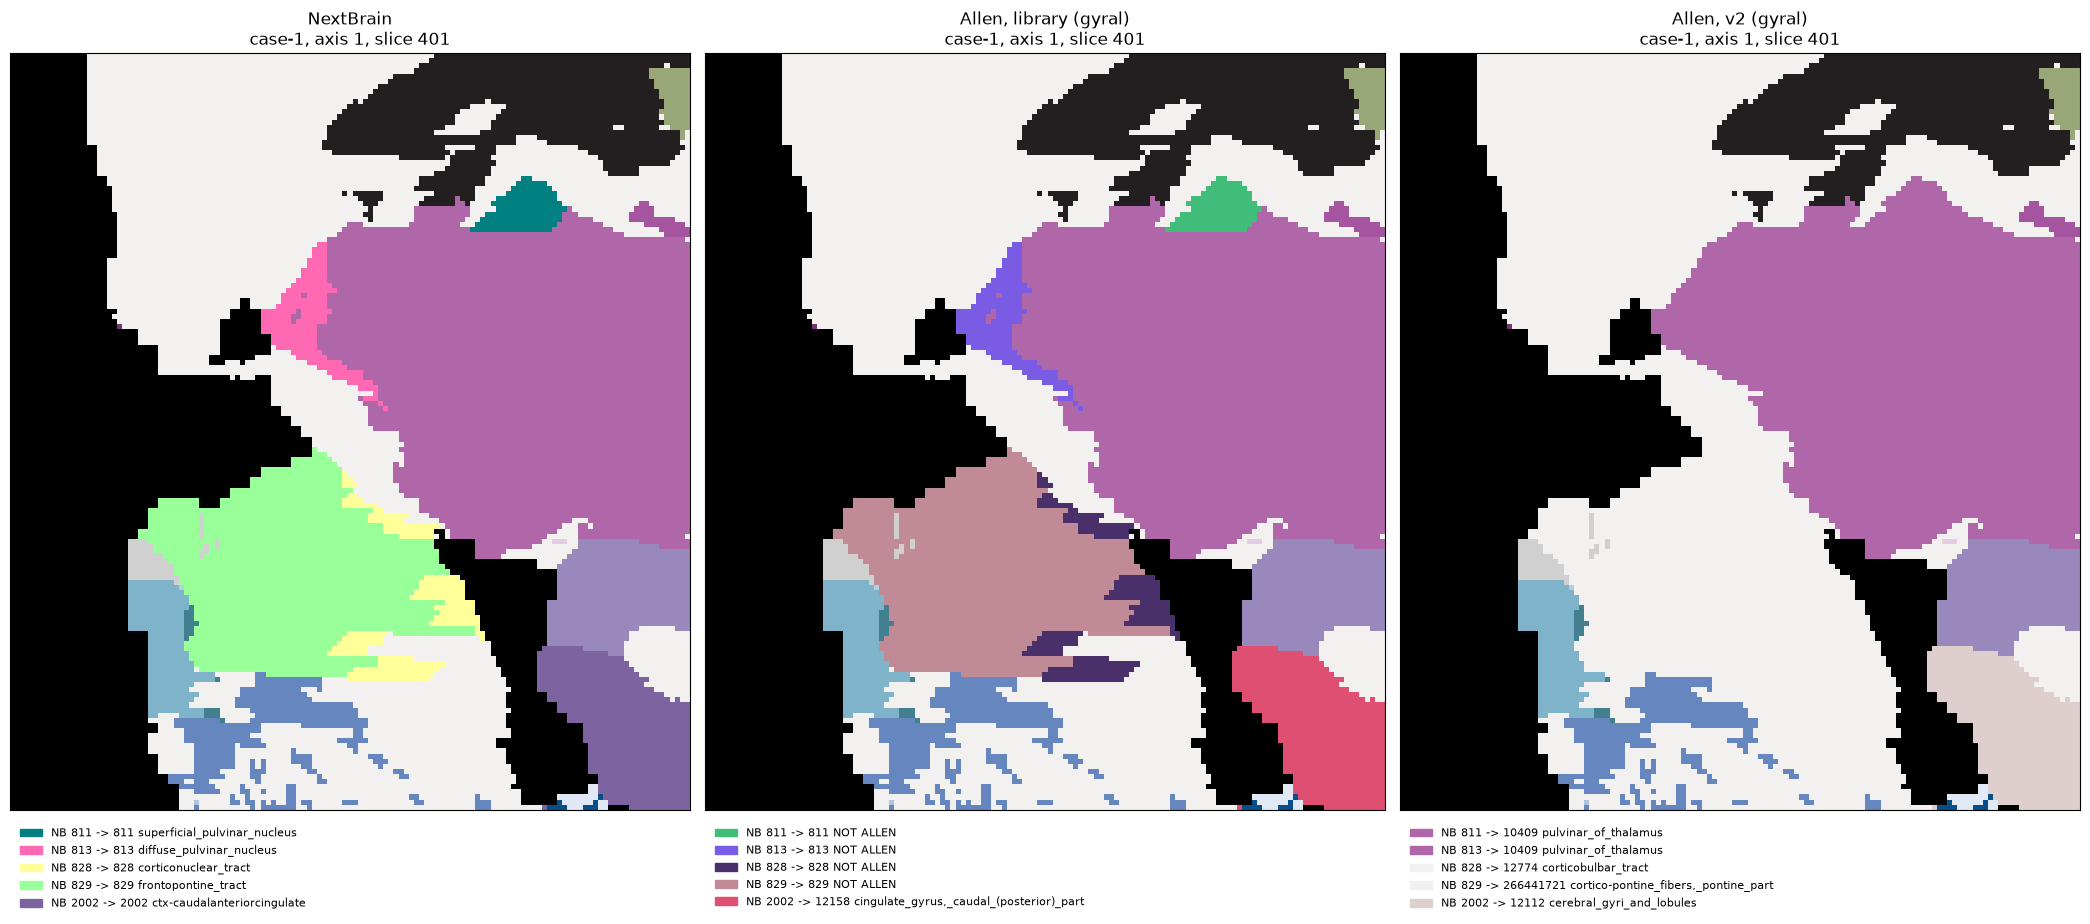

fixed labels visible in this slice: [811, 813, 828, 829, 2002]


In [23]:
from matplotlib.patches import Patch
seg = np.asarray(nib.load(CASES[0]).dataobj)
fixed = sorted(OV)                                   # labels changed by v2
mask = np.isin(seg, [x for x in fixed if x != 2002])
axis = 1
idx = int(np.argmax(mask.sum(axis=tuple(a for a in range(3) if a != axis))))
sl = np.take(seg, idx, axis=axis)
ii, jj = np.nonzero(np.take(mask, idx, axis=axis))
pad = 25
sl = sl[max(ii.min() - pad, 0): ii.max() + pad, max(jj.min() - pad, 0): jj.max() + pad]

nb_c = H.lut_dict(nxb_lut)
al_c = H.lut_dict(allen_lut())
def rgb(img, lut):
    out = np.zeros(img.shape + (3,), np.uint8)
    for v in np.unique(img):
        if v: out[img == v] = lut.get(int(v), (None, H._fallback_color(v)))[1]
    return out

panels = [("NextBrain", sl, nb_c, lambda x: x),
          ("Allen, library (gyral)", LIB["gyral"][sl], al_c, lambda x: int(LIB["gyral"][x])),
          ("Allen, v2 (gyral)", M2[sl], al_c, lambda x: int(M2[x]))]
fig, axes = plt.subplots(1, 3, figsize=(21, 9))
in_slice = [x for x in fixed if (sl == x).any()]
for ax, (title, img, lut, f) in zip(axes, panels):
    ax.imshow(rgb(img, lut).transpose(1, 0, 2), origin="lower", interpolation="nearest")
    ax.set_title(f"{title}\ncase-1, axis {axis}, slice {idx}"); ax.set_xticks([]); ax.set_yticks([])
    hs = []
    for x in in_slice:
        v = f(x)
        name, col = lut.get(v, ("NOT ALLEN", H._fallback_color(v)))
        hs.append(Patch(color=np.array(col) / 255, label=f"NB {x} -> {v} {name}"[:60]))
    ax.legend(handles=hs, loc="upper left", bbox_to_anchor=(0, -0.01), fontsize=8, frameon=False)
plt.tight_layout(); plt.show()
print("fixed labels visible in this slice:", in_slice)

## 6 · Summary

**How a label is converted:**
`nextbrain2allen = identity` → normalise the names → (cortex only) swap in the hand-table
target name → depth-first walk of the Allen tree, overwriting on every exact normalised-name
match (last match wins) → optionally strip the ID prefixes for `int16` → look up every voxel.

**On the test data (300 foreground labels):**

| | labels | what happens | fix |
|---|---|---|---|
| R1 OK | 288 | exact normalised-name match, unique in Allen | none |
| **P1** 2002 | 1 (≈ half the foreground voxels) | crash; when patched, the whole cortex becomes *caudal cingulate* | → *cerebral gyri and lobules* (gyral) / *cerebral cortex* (dev, dk) |
| **P2** ambiguous | 2 (377, 521) | last match wins → **wrong structure** (pons instead of amygdala / midbrain) | explicit override to the correct node |
| **P3** unmatched | 7 | NextBrain ID left in the output, no warning | synonym / spelling / parent-node overrides |
| **P4** s16 collision | 2 of P3 (828, 844) | s16 ID equals an Allen sulcus ID | solved by P3 |
| **P6** cerebellar cortex | 2 (595, 597) | the whole cerebellar cortex becomes *paravermis, anterior lobe* (right layer, wrong place) | → `cerebellar cortex` (A) or two custom layer labels (B); not applied yet |
| P5 non-leaf | 95 | inner Allen node, correct concept | none (relevant for 05) |

**Suggested library changes (`to_allen.py`):**

1. `cortex_map[key[7:]]` → `cortex_map[normalize_name(key)]` (removes the `ctx-` crash).
2. Lowercase the hand-table targets, or compare `normalize_name(target)`, to fix 2034 / Heschl.
3. Warn when a NextBrain name matches **more than one** Allen node, or none.
4. Add an `overrides` argument (or a built-in table like `OVERRIDES_COMMON`) for synonyms,
   spelling variants and ambiguous names.
5. Upstream (create_merged_segmentations): map label 3 to Allen *cerebral cortex*
   directly, instead of the 2002 placeholder.